# Домашка 2: база знаний по матчам ЧМ-2026, выполненный прогон

Ноутбук вызывает те же функции, что и скрипты, описанные в [README.md](README.md). Платный только раздел с памятью, около $0.004: эмбеддинги берутся из кэша `emb_cache.npz`, ответы моделей на квиз — из `data/eval_results.jsonl` и `data/week1_baseline.jsonl`. Нужен Milvus (`docker compose up -d`) и `OPENROUTER_API_KEY` в `.env`.

In [1]:
import sys
sys.argv = ["main.py"]  # main.main() разбирает аргументы командной строки, а у ядра свои

import load_index, main, memory
from load_index import ledger

## Шаг 2. Нарезки, индекс в Milvus, recall@k и гибрид

Обе коллекции пересобираются с нуля. Все векторы уже в кэше, поэтому повторный запуск стоит $0: в конце `итого потрачено $0.000000`.

In [2]:
load_index.main()

2026-10-16 18:30:47,680 INFO кэш эмбеддингов: 1889 векторов


lines: 635 кусков, векторы (635, 512), в Milvus chunks_lines: 635


chars: 693 кусков, векторы (693, 512), в Milvus chunks_chars: 693


    lines  chars
1    0.92   0.78
3    0.98   0.96
4    1.00   0.99
5    1.00   0.99
10   1.00   1.00
20   1.00   1.00
график: /home/bendereg/Documents/AI-agents/Поступашки/02_Memory/img/recall.png


              recall@1  recall@3  recall@5
vector only       0.78      0.96      0.99
keyword only      0.69      0.86      0.91
hybrid RRF        0.77      0.92      0.97
график: /home/bendereg/Documents/AI-agents/Поступашки/02_Memory/img/search_chars.png


2026-10-16 18:30:58,608 INFO в лог леджера записано 0 вызовов


итого потрачено $0.000000


### Фильтр по стадии

`knowledge_base` с `stage` возвращает куски только этой стадии, с выдуманной стадией — `nothing found`.

In [3]:
print(load_index.knowledge_base("referee", "2026 FIFA World Cup Group A"))
print()
print(load_index.knowledge_base("final score", "2026 FIFA World Cup Group Z"))

[2026 FIFA World Cup Group A / South Korea vs Czech Republic] Man of the Match: Hwang In-beom (South Korea) [ 14 ] Assistant referees : [ 19 ] Mahmoud Abouregal ( Egypt ) Ahmed Hossam Taha ( Egypt ) Fourth official : Juan Gabriel Calderón ( Costa Rica ) Reserve assistant referee : Juan Carlos Mora ( Costa Rica ) Video assistant referee : Mahmoud Ashour ( Egypt ) Assistant video assistant referee : Joe Dickerson ( United States ) Support video assistant referee : Marco Di Bello ( Italy ) (https://en.wikipedia.org/wiki/2026_FIFA_World_Cup_Group_A#South_Korea_vs_Czech_Republic)
[2026 FIFA World Cup Group A / Czech Republic vs South Africa] By officiating this match, referees Tori Penso , Brooke Mayo , and Kathryn Nesbitt became the second all-female on-field refereeing trio, and the first from the United States, to take charge of a match at a men's FIFA World Cup. [ 21 ] (https://en.wikipedia.org/wiki/2026_FIFA_World_Cup_Group_A#Czech_Republic_vs_South_Africa)
[2026 FIFA World Cup Group A

## Шаг 3. Пять конфигураций, отказы, разбор провалов

Две строки прошлой недели собраны `import_week1.py` из трейсов первой домашки и проверены той же `is_correct`. Отказ определяется по строке `FINAL`.

In [4]:
main.main()

2026-10-16 18:30:58,672 INFO кэш эмбеддингов: 1889 векторов


2026-10-16 18:30:58,699 INFO беру готовые ответы из /home/bendereg/Documents/AI-agents/Поступашки/02_Memory/data/eval_results.jsonl, для нового прогона запустите с --rerun


                    config             model   n  accuracy  cost_per_task  searches  cost_per_correct
без инструментов, неделя 1 claude-sonnet-4.6 104  0.192308       0.005633  0.000000          0.029289
     живой поиск, неделя 1       gpt-4o-mini 104  0.461538       0.000935  4.980769          0.002027
                RAG всегда       gpt-4o-mini 104  0.884615       0.000137  1.000000          0.000155
    агент с knowledge_base       gpt-4o-mini 104  0.788462       0.000727  2.115385          0.000922
                RAG всегда  claude-haiku-4.5 104  1.000000       0.001317  1.000000          0.001317
                    config             model честно отклонил отклонил зря
без инструментов, неделя 1 claude-sonnet-4.6               —     58 / 104
     живой поиск, неделя 1       gpt-4o-mini               —     46 / 104
                RAG всегда       gpt-4o-mini         10 / 10      8 / 104
    агент с knowledge_base       gpt-4o-mini         10 / 10     21 / 104
                RA

2026-10-16 18:30:59,365 INFO в лог леджера записано 0 вызовов


график: /home/bendereg/Documents/AI-agents/Поступашки/02_Memory/img/money_chart.png

разбор провалов, лучшая конфигурация: RAG всегда / claude-haiku-4.5
                                      поиск не нашёл  нашёл, но ответ неверный
RAG всегда / claude-haiku-4.5                      0                         0
RAG всегда / gpt-4o-mini                           0                        12
агент с knowledge_base / gpt-4o-mini              20                         2

=== поиск не нашёл (агент с knowledge_base / gpt-4o-mini): fresh-1
вопрос: What FIFA World Cup milestone was reached in the Tunisia vs Japan group stage match?
эталон: 1,000th World Cup match
цитата: This fixture was the 1,000th World Cup match, with the previous milestone (900th) having been reached in the 2018 FIFA World Cup final.
ответ модели: I couldn't find specific information about a milestone reached in the Tunisia vs Japan group stage match of the 2026 FIFA World Cup. FINAL: NOT_FOUND
контекст:
[2026 FIFA World Cup

## Шаг 4. Память: три сессии

Каждая сессия начинается с пустой истории. Во второй и третьей агент знает о пользователе только факты из коллекции Milvus `facts`. Во второй сессии пользователь меняет любимую сборную, и после неё в памяти лежит новый факт вместо старого.

In [5]:
from datetime import datetime

memory.load_cache()
mem, run = memory.FactMemory(), datetime.now().strftime("%Y%m%d-%H%M%S")
mem.reset()

s1, first = f"{run}/s1", []
memory.say(s1, first, mem, "Привет! Меня зовут Женя, я из Москвы и болею за сборную Японии. Отвечай коротко.")
memory.say(s1, first, mem, "Какой юбилей турнира случился в матче Тунис — Япония?")
memory.print_facts("факты после сессии 1", memory.end_session(s1, mem))

2026-10-16 18:31:02,299 INFO ledger dialog: окно плюс факты openai/gpt-4o-mini prompt=398 cost=$0.000069



[20261016-183059/s1] пользователь: Привет! Меня зовут Женя, я из Москвы и болею за сборную Японии. Отвечай коротко.
  факты из памяти: нет
  агент: Привет, Женя! Рад помочь. Какой у тебя вопрос?


2026-10-16 18:31:03,856 INFO ledger dialog: окно плюс факты openai/gpt-4o-mini prompt=440 cost=$0.000081


2026-10-16 18:31:05,089 INFO ledger dialog: окно плюс факты openai/gpt-4o-mini prompt=1261 cost=$0.000208



[20261016-183059/s1] пользователь: Какой юбилей турнира случился в матче Тунис — Япония?
  факты из памяти: нет
  агент: В матче Тунис — Япония произошел юбилей: это была 1000-я игра в истории чемпионатов мира по футболу.


2026-10-16 18:31:08,249 INFO ledger memory openai/gpt-4o-mini prompt=294 cost=$0.000078


2026-10-16 18:31:08,966 INFO ledger embed:memory openai/text-embedding-3-small prompt=7 cost=$0.000000



факты после сессии 1:
  answer_style: Просит отвечать коротко
  city: Из Москвы
  favorite_team: Болеет за сборную Японии
  name: Зовут Женя


In [6]:
s2, second = f"{run}/s2", []
memory.say(s2, second, mem, "Кто забил за мою сборную в матче с Нидерландами?")
memory.say(s2, second, mem, "Японию я больше не смотрю, теперь болею за сборную Марокко.")
memory.print_facts("факты после сессии 2", memory.end_session(s2, mem))

2026-10-16 18:31:12,470 INFO ledger dialog: окно плюс факты openai/gpt-4o-mini prompt=414 cost=$0.000074


2026-10-16 18:31:13,641 INFO ledger dialog: окно плюс факты openai/gpt-4o-mini prompt=1240 cost=$0.000211



[20261016-183059/s2] пользователь: Кто забил за мою сборную в матче с Нидерландами?
  факты из памяти: ['Болеет за сборную Японии', 'Просит отвечать коротко', 'Из Москвы']
  агент: В матче с Нидерландами за сборную Японии забили Накамура (57') и Камада (88'). Матч закончился вничью 2:2.


2026-10-16 18:31:14,905 INFO ledger dialog: окно плюс факты openai/gpt-4o-mini prompt=482 cost=$0.000092



[20261016-183059/s2] пользователь: Японию я больше не смотрю, теперь болею за сборную Марокко.
  факты из памяти: ['Болеет за сборную Японии', 'Из Москвы', 'Зовут Женя']
  агент: Понял, теперь вы болеете за сборную Марокко! Если у вас есть вопросы о матчах или игроках, дайте знать!


2026-10-16 18:31:16,382 INFO ledger memory openai/gpt-4o-mini prompt=353 cost=$0.000087



факты после сессии 2:
  answer_style: Просит отвечать коротко
  city: Из Москвы
  favorite_team: Болеет за сборную Марокко
  name: Зовут Женя


In [7]:
s3, third = f"{run}/s3", []
memory.say(s3, third, mem, "Кто забил автогол в матче моей сборной с Гаити?")
print(f"\nфактов в коллекции: {len(mem.all())}")

2026-10-16 18:31:17,541 INFO ledger dialog: окно плюс факты openai/gpt-4o-mini prompt=412 cost=$0.000073


2026-10-16 18:31:18,751 INFO ledger dialog: окно плюс факты openai/gpt-4o-mini prompt=1270 cost=$0.000210



[20261016-183059/s3] пользователь: Кто забил автогол в матче моей сборной с Гаити?
  факты из памяти: ['Болеет за сборную Марокко', 'Из Москвы', 'Зовут Женя']
  агент: Автогол в матче Марокко с Гаити забил Яссин Буну в 10-й минуте первого тайма.

фактов в коллекции: 4


### Токены: вся история против окна с фактами

Замер из README (`memory.token_bench`, 12 реплик двумя способами) стоит около $0.016. По умолчанию показываем сохранённый график того прогона, на нём построена таблица в README. `RUN_TOKEN_BENCH = True` повторит замер.

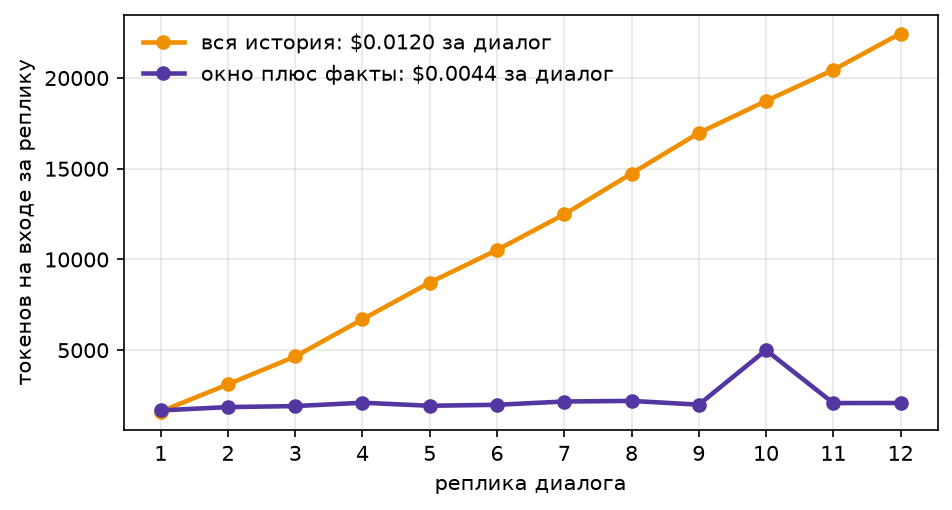

In [8]:
from IPython.display import Image

RUN_TOKEN_BENCH = False
if RUN_TOKEN_BENCH:
    by_id = {t["id"]: t for t in load_index.load_jsonl("match_quiz_evaluated.jsonl")}
    bench = memory.token_bench([by_id[i]["question"] for i in memory.BENCH_IDS], mem)
    print(bench.groupby("mode", sort=False).agg(calls=("calls", "sum"), prompt=("prompt", "sum"), cost=("cost", "sum")))
    memory.plot_tokens(bench)
Image(memory.TOKENS_PNG)

## Сколько стоил прогон ноутбука

In [9]:
memory.save_cache()
print(f"записано в журнал цены: {ledger.save()} вызовов")
print(ledger.table().to_string())
print(f"итого потрачено ${ledger.total:.6f}")

записано в журнал цены: 11 вызовов
                                                calls  prompt  completion     cost
tag                     model                                                     
dialog: окно плюс факты gpt-4o-mini                 8    5917         220  0.00102
embed:memory            text-embedding-3-small      1       7           0  0.00000
memory                  gpt-4o-mini                 2     647         114  0.00017
итого потрачено $0.001185
